<a href="https://colab.research.google.com/github/vicentepellicer/Alquilerpatinetes/blob/master/Algoritmo_FIFO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ingrese la cantidad de procesos: 3
Ingrese el tiempo de llegada del proceso P1: 2
Ingrese el tiempo de ejecución del proceso P1: 3
Ingrese el tiempo de llegada del proceso P2: 2
Ingrese el tiempo de ejecución del proceso P2: 3
Ingrese el tiempo de llegada del proceso P3: 2
Ingrese el tiempo de ejecución del proceso P3: 3

Tabla de resultados:


,Proceso,Llegada,Ráfaga,Inicio,Fin,Espera,Finalización,Penalización
0,P1,2,3,2,5,0,3,1.00
1,P2,2,3,5,8,3,6,2.00
2,P3,2,3,8,11,6,9,3.00



Tiempo promedio de espera: 3.00
Tiempo promedio de finalización: 6.00
Penalización promedio: 2.00


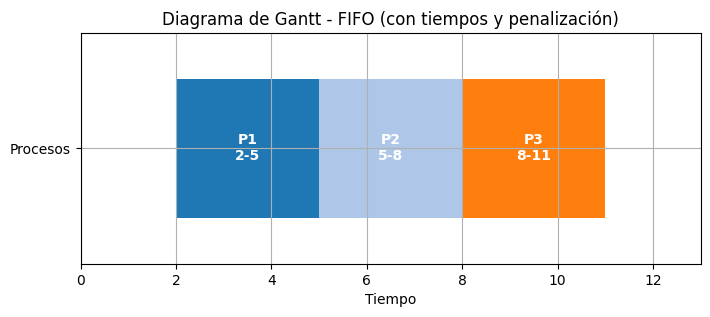

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd # Importamos pandas para una mejor visualización de la tabla

# --- 1. Inicialización e Entrada de Datos ---

# Pedimos la cantidad de procesos
n = int(input("Ingrese la cantidad de procesos: "))

arrival_times = []
burst_times = []

# Ingreso de tiempos de llegada y ejecución para cada proceso
for i in range(n):
    at = int(input(f"Ingrese el tiempo de llegada del proceso P{i+1}: "))
    bt = int(input(f"Ingrese el tiempo de ejecución del proceso P{i+1}: "))
    arrival_times.append(at)
    burst_times.append(bt)

# Inicializamos variables para almacenar los resultados
start_times = [0]*n         # Tiempo en que cada proceso comienza su ejecución
completion_times = [0]*n    # Tiempo en que cada proceso finaliza su ejecución
waiting_times = [0]*n       # Tiempo que cada proceso espera antes de ejecutarse
turnaround_times = [0]*n    # Tiempo total desde la llegada hasta la finalización (Completion - Arrival)
penalty_ratios = [0]*n      # Relación de penalización (Turnaround / Burst)

# --- 2. Lógica FIFO (FCFS) ---

# Ordenamos los procesos por su tiempo de llegada (FCFS)
# `processes` contendrá los índices originales de los procesos ordenados
processes = list(range(n))
processes.sort(key=lambda x: arrival_times[x])

current_time = 0  # El tiempo actual del "CPU"
gantt_chart = []  # Lista para construir la información del Diagrama de Gantt

# Simulamos la ejecución de los procesos
for p in processes:
    # Si el CPU está "ocioso" antes de la llegada del proceso, avanzamos el tiempo
    if current_time < arrival_times[p]:
        current_time = arrival_times[p]

    start_times[p] = current_time                              # El proceso inicia ahora
    completion_times[p] = current_time + burst_times[p]        # El proceso finaliza después de su ráfaga
    waiting_times[p] = start_times[p] - arrival_times[p]       # Tiempo de espera
    turnaround_times[p] = completion_times[p] - arrival_times[p] # Tiempo de finalización total
    penalty_ratios[p] = turnaround_times[p] / burst_times[p]   # Relación de penalización

    current_time += burst_times[p]                             # El tiempo del CPU avanza por la ráfaga del proceso
    # Guardamos la información para el diagrama de Gantt
    gantt_chart.append((f'P{p+1}', start_times[p], completion_times[p]))

# --- 3. Resultados y Promedios ---

# Creamos un DataFrame para mostrar los resultados de manera más clara
results_data = {
    "Proceso": [f"P{i+1}" for i in range(n)],
    "Llegada": arrival_times,
    "Ráfaga": burst_times,
    "Inicio": start_times,
    "Fin": completion_times,
    "Espera": waiting_times,
    "Finalización": turnaround_times,
    "Penalización": [f"{pr:.2f}" for pr in penalty_ratios] # Formateamos a 2 decimales para la tabla
}
df_results = pd.DataFrame(results_data)

print("\nTabla de resultados:")
display(df_results)

# Calculamos los promedios de las métricas clave
avg_waiting_time = sum(waiting_times) / n
avg_turnaround_time = sum(turnaround_times) / n
avg_penalty = sum(penalty_ratios) / n

print(f"\nTiempo promedio de espera: {avg_waiting_time:.2f}")
print(f"Tiempo promedio de finalización: {avg_turnaround_time:.2f}")
print(f"Penalización promedio: {avg_penalty:.2f}")

# --- 4. Diagrama de Gantt ---

# Dibujamos el diagrama de Gantt adaptable
fig, gnt = plt.subplots(figsize=(max(8, n*2),3))
gnt.set_ylim(0, 10)
gnt.set_xlim(0, max(completion_times)+2) # El límite del eje X se ajusta al tiempo máximo de finalización
gnt.set_xlabel('Tiempo')
gnt.set_yticks([5])
gnt.set_yticklabels(['Procesos']) # Etiqueta para el eje Y
gnt.grid(True) # Añadimos una cuadrícula

# Generamos colores únicos para cada proceso para una mejor visualización
colors = [plt.cm.tab20(i % 20) for i in range(n)]

# Dibujamos las barras para cada proceso en el diagrama de Gantt
for i, task in enumerate(gantt_chart):
    start = task[1]
    end = task[2]
    # Dibuja una barra para cada tarea (proceso)
    gnt.broken_barh([(start, end-start)], (2, 6), facecolors=(colors[i]))
    # Añade el texto del proceso y sus tiempos dentro de la barra
    gnt.text((start+end)/2, 5, f"{task[0]}\n{start}-{end}", color='white', weight='bold', ha='center', va='center')

plt.title("Diagrama de Gantt - FIFO (con tiempos y penalización)")
plt.show()
